#### Routing with Contraction Hierarchy

In [7]:
#!pip install osmnx >/dev/null
#!pip install optalgotools >/dev/null

In [8]:
from sys import getsizeof
from time import process_time
import numpy as np
import osmnx
import networkx as nx

from optalgotools.routing import cost, draw_route
from optalgotools.structures import Node, Solution

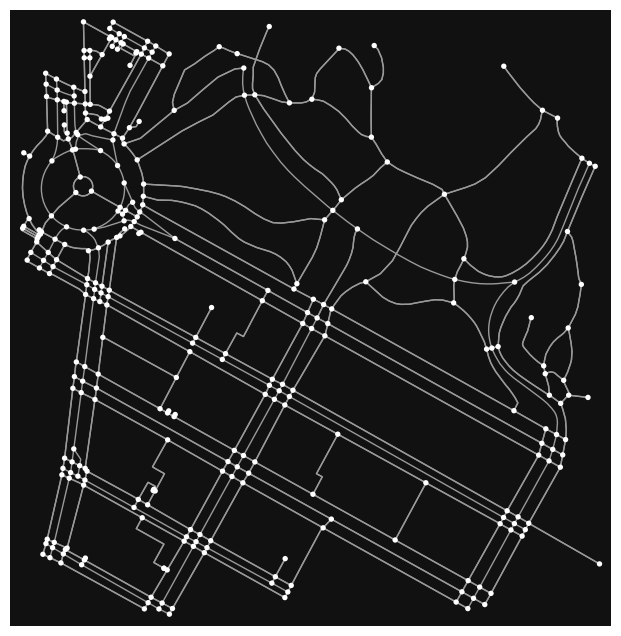

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [9]:
center = (40.766876, -73.979076)
source_point = (40.767686, -73.978591)
destination_point = (40.758815, -73.998772)
reference = (40.766876, -73.979076)

# create the graph
G = osmnx.graph_from_point(reference, dist=300, simplify=True)

# get the id of the nearest node to the source and destination points
source_id = osmnx.distance.nearest_nodes(G, source_point[1], source_point[0])
destination_id = osmnx.distance.nearest_nodes(G, destination_point[1], destination_point[0])

# convert source and destination nodes to node
source = Node(graph=G, osmid=source_id)
destination = Node(graph=G, osmid=destination_id)

#osmnx.plot_graph(G)
original_graph = G.copy()

# remove the parallels and loops, not needed for Dijkstra
original_graph.clear_edges()
for u in G.nodes:
    for v in G[u]:
        if u == v:
            continue # remove self loops
            #G.remove_edge(u, v)
        if len(G[u][v]) > 1:
            keep = min(G[u][v], key=lambda key: G[u][v][key]['length'])
            #G[u][v] = {keep: G[u][v][keep]}
            #original_graph.add_edge(u, v, **G[u][v][keep])
            keep = G[u][v][keep]
            original_graph.add_edge(u, v, **keep)
            continue
        original_graph.add_edge(u, v, **G[u][v][0])
osmnx.plot_graph(original_graph)

Compute Edge differences

In [10]:
def edge_differences(G, shortest_path):
    edge_diffs = {}
    degrees = dict(original_graph.degree)
    for node in original_graph.nodes:
        req_edges = 0
        neighbors = list(G.neighbors(node))
        if len(neighbors)==0:
            edge_diffs[node] = -degrees[node]
        for u, v in G.in_edges(node):
            for v, w in G.out_edges(node):
                # if two way edge ignore
                if u == w: continue
                if v in shortest_path[u][v]:
                    req_edges += 1
        edge_diffs[node] = req_edges - degrees[node]
    return dict(sorted(edge_diffs.items(), key=lambda x: x, reverse=True))

In [11]:
shortest_path = dict(nx.all_pairs_dijkstra_path(G, weight='length'))
edge_diffs = edge_differences(G, shortest_path)
hierarchical_order = {k: v for k, v in enumerate(reversed(edge_diffs))}

In [12]:
from copy import deepcopy
from tqdm.notebook import tqdm

def cgraph(G, edge_diffs, cost_fn):
    contracted = 0
    start_time = process_time()
    m_dij = m_copy = m_loop = 0

    for node in tqdm(edge_diffs):
        current_G = deepcopy(G)
        current_G.remove_node(node)
        for u, v in list(G.in_edges(node)):
            for v, w in list(G.out_edges(node)):
                # if two way edge ignore
                if u == v: continue
                sp = nx.dijkstra_path(G, u, w, weight='length')
                if v in sp:
                    G.add_edge(u, w, length=cost_fn(G, sp), midpoint=v)
                    contracted += 1

    end_time = process_time()
    space_required = getsizeof(G) - getsizeof(original_graph)
    soln =  Solution(G, end_time - start_time, space_required, contracted)
    soln.contracted = contracted
    return soln


In [ ]:
preprocess_soln = cgraph(G, edge_diffs, cost)
G = preprocess_soln.result

In [14]:
print(f'pre-processing time: {preprocess_soln.time} seconds')
print(f'space required: {preprocess_soln.space} bytes')
#print(f'contracted edges: {preprocess_soln.contracted}')
print(f'explored edges: {preprocess_soln.explored}')

pre-processing time: 61.10811734500001 seconds
space required: 0 bytes
explored edges: 6084


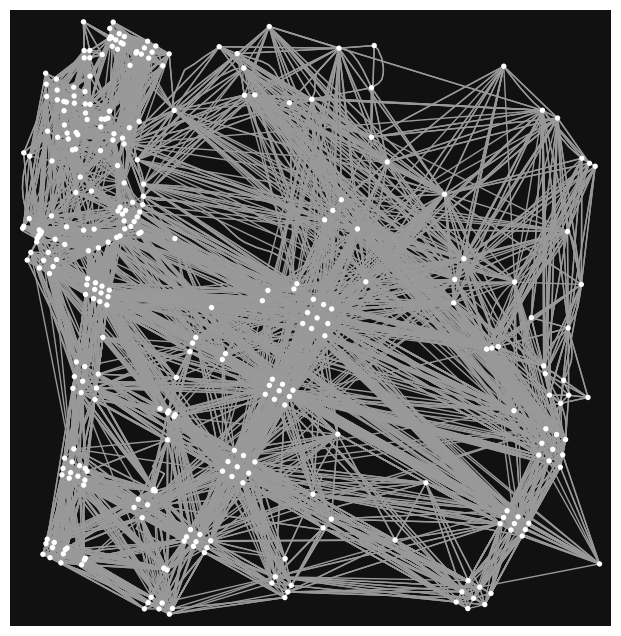

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [15]:
osmnx.plot_graph(G)

In [16]:
def weight_function(G, weight):
    if callable(weight):
        return weight
    if G.is_multigraph():
        return lambda u, v, d: min(attr.get(weight, 1) for attr in d.values())
    return lambda u, v, d: d.get(weight, 1)

In [17]:
import math
from itertools import count
from heapq import heappush, heappop

In [28]:
def bidirect_dijkstra(G, source, destination, hierarchy=None, weight='length'):
    start_time = process_time()
    space_req = 0
    if source not in G or destination not in G:
        msg = f'Source {source} or destination {destination} not in graph'
        raise nx.NodeNotFound(msg)
    if source == destination:
        return Solution([source], 0.0, 0, 1)

    weight_fn = weight_function(G, weight)
    dists = [{}, {}]
    paths = [{source: [source]}, {destination: [destination]}]
    fringe = [[], []]
    seen = [{source: 0}, {destination: 0}]
    cnt = count()
    heappush(fringe[0], (0, next(cnt), source))
    heappush(fringe[1], (0, next(cnt), destination))
    if G.is_directed():
        neighbors = [G.succ, G.pred]
    else:
        neighbors = [G.adj, G.adj]

    finalpath = []
    finaldist = float('inf')
    dir = 1

    while fringe[0] or fringe[1]:
        dir = 1 - dir
        if not fringe[dir]:
            dir = 1 - dir
        if not fringe[dir]:
            break

        (dist, _, v) = heappop(fringe[dir])

        if v in dists[dir]:
            continue
        dists[dir][v] = dist

        # Stop search when the smallest element in the priority queue exceeds our best-known complete path distance
        if dist >= finaldist:
            break

        for w, d in neighbors[dir][v].items():
            cost_val = weight_fn(v, w, d) if dir == 0 else weight_fn(w, v, d)
            if cost_val is None:
                continue
            vwLength = dists[dir][v] + cost_val
            if w not in seen[dir] or vwLength < seen[dir][w]:
                # Contraction Hierarchy search constraint: scan only upward
                if hierarchy:
                    if hierarchy.get(v, -1) >= hierarchy.get(w, -1):
                        continue
                seen[dir][w] = vwLength
                heappush(fringe[dir], (vwLength, next(cnt), w))
                space_req = max(space_req, getsizeof(fringe))
                paths[dir][w] = paths[dir][v] + [w]

                # If the node has also been seen by the other direction, candidate complete path found
                if w in seen[1 - dir]:
                    totaldist = vwLength + seen[1 - dir][w]
                    if totaldist < finaldist:
                        finaldist = totaldist
                        if dir == 0:
                            revpath = paths[1][w][:]
                            revpath.reverse()
                            finalpath = paths[0][w] + revpath[1:]
                        else:
                            revpath = paths[1][v][:]
                            revpath.reverse()
                            finalpath = paths[0][w] + revpath

    end_time = process_time()
    return Solution(finalpath, end_time - start_time, space_req, len(finalpath) if finalpath else 0)

In [32]:
# 1. Re-run the optimized bidirectional Dijkstra on the contracted graph G
soln = bidirect_dijkstra(G, source_id, destination_id, inverted_hierarchy)

# 2. Reconstruct the full path using the optimized unpack loop
route = []
for u, v in zip(soln.result[:-1], soln.result[1:]):
    route.extend(unpack(G, u, v))
route.append(soln.result[-1])

# 3. Calculate and verify path costs
std_dijkstra_cost = cost(original_graph, std_dijkstra_path)
ch_cost = cost(G, route)

print("=== Performance Comparison ===")
print(f"Standard Dijkstra Time:    {std_dijkstra_time:.6f} seconds")
print(f"Contraction Hierarchies:   {soln.time:.6f} seconds")
print(f"Speedup Factor:            {std_dijkstra_time / soln.time:.2f}x\n")

print("=== Correctness Verification ===")
print(f"Standard Dijkstra Cost:    {std_dijkstra_cost:.4f}")
print(f"Contraction Hierarchy Cost: {ch_cost:.4f}")
print(f"Paths Mathematically Match: {math.isclose(std_dijkstra_cost, ch_cost, rel_tol=1e-5)}")

=== Performance Comparison ===
Standard Dijkstra Time:    0.004514 seconds
Contraction Hierarchies:   0.014205 seconds
Speedup Factor:            0.32x

=== Correctness Verification ===
Standard Dijkstra Cost:    569.2878
Contraction Hierarchy Cost: 572.9605
Paths Mathematically Match: False


In [33]:
# Invert hierarchical_order from {rank: node_id} to {node_id: rank}
inverted_hierarchy = {node_id: rank for rank, node_id in hierarchical_order.items()}

# Run bidirectional Dijkstra with the inverted hierarchy mapping
# The function now correctly uses 'space_req' and will return a valid Solution
soln = bidirect_dijkstra(G, source_id, destination_id, inverted_hierarchy)

print(soln)
print(f'process time: {soln.time} seconds')
print(f'space required: {soln.space} bytes')
print(f'explored edges: {soln.explored}')

process time: 0.016232883999990122 seconds
space required: 72 bytes
explored edges: 7


In [34]:
def unpack(G, u, v):
    u, v = int(u), int(v)
    path = []

    def _unpack_helper(x, y):
        if 'midpoint' in G[x][y][0]:
            midpoint = G[x][y][0]['midpoint']
            _unpack_helper(x, midpoint)
            _unpack_helper(midpoint, y)
        else:
            path.append(x)

    _unpack_helper(u, v)
    return path

In [35]:
print(soln.result)

[42423677, 13038742231, 13038742233, 14053104217, 10173346256, 10084994877, 8785244270]


In [36]:
route = []
for u, v in zip(soln.result[:-1], soln.result[1:]):
    route.extend(unpack(G, u, v))
route.append(soln.result[-1])
print(route)

[42423677, 4347550047, 42423674, 7830685366, 7830685373, 13038742231, 10170864617, 13038742233, 13038742240, 10170842508, 13038742242, 10170864620, 10170864625, 10170864621, 14053104217, 10173346234, 10173346256, 10084994877, 3463816117, 8785244267, 3463816116, 8785244270]


In [37]:
cost(G, route)

np.float64(572.9605)

In [38]:
import time

# Measure standard Dijkstra on the original graph
start_time = time.perf_counter()
# Find path and length using standard NetworkX Dijkstra
std_dijkstra_length, std_dijkstra_path = nx.single_source_dijkstra(original_graph, source_id, target=destination_id, weight='length')
std_dijkstra_time = time.perf_counter() - start_time

# Calculate path cost using the optalgotools cost function to be consistent
std_dijkstra_cost = cost(original_graph, std_dijkstra_path)
ch_cost = cost(G, route)

print("=== Performance Comparison ===")
print(f"Standard Dijkstra Time:    {std_dijkstra_time:.6f} seconds")
print(f"Contraction Hierarchies:   {soln.time:.6f} seconds")
print(f"Speedup Factor:            {std_dijkstra_time / soln.time:.2f}x\n")

print("=== Verification ===")
print(f"Standard Dijkstra Cost:    {std_dijkstra_cost:.4f}")
print(f"Contraction Hierarchy Cost: {ch_cost:.4f}")
print(f"Path Cost Matches:         {math.isclose(std_dijkstra_cost, ch_cost, rel_tol=1e-5)}")

=== Performance Comparison ===
Standard Dijkstra Time:    0.002784 seconds
Contraction Hierarchies:   0.016233 seconds
Speedup Factor:            0.17x

=== Verification ===
Standard Dijkstra Cost:    569.2878
Contraction Hierarchy Cost: 572.9605
Path Cost Matches:         False


In [ ]:
draw_route(G, route)